###  Libraries

In [1]:
# Import libraries
import numpy as np
import torch
import sys
from Datasets.Datasets import get_dataset
from Autoencoder import Autoencoder, CD_Autoencoder
from Visualization import Visualization
from General_Functions import General_Functions

### Global Variables

In [2]:
# Set path to module
path_to_module = './'
sys.path.append(path_to_module)

# Set device (cuda or cpu)
device = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')
if torch.cuda.is_available():
    torch.cuda.set_device(device)

# Set random seeds (runs repeat only from a fresh kernel with all cells run in order) - for more info look here : https://docs.pytorch.org/docs/2.15/notes/randomness.html
seed = 42
torch.manual_seed(seed) # torch, CPU and GPU: layer weights, RBF centres, batch order of the dataloader
np.random.seed(seed) # numpy: k-means initialization, t-SNE, plot colours . Careful , when dataset = "synthetic" it overrides the seed to 42 !!!
torch.backends.cudnn.deterministic = True # GPU: cuDNN uses only deterministic convolution algorithms
torch.backends.cudnn.benchmark = False # GPU: cuDNN does not test and pick a (possibly different) fastest algorithm each run

### Visualization

In [3]:
visualization = Visualization()

### Load Dataset

In [4]:
# Set dataset_name, module_name, batch_size and n_clusters
dataset_name = "emnist_balanced_digits" # The available datasets are: emnist_balanced_digits, emnist_mnist, emnist_balanced_letters_A_J, emnist_balanced_letters_K_T, emnist_balanced_letters_U_Z, har, pendigits, waveform_v1, synthetic
batch_size = 256
n_clusters = 10

# Get dataloader, input_dim, data_np and labels
dataloader, input_dim, data_np, labels = get_dataset(dataset_name, batch_size)
print('Data_Shape is:', input_dim) # for image datasets , data shape == channel
print('Batches Number is:', len(dataloader))
print(np.unique(labels))

Data_Shape is: 1
Batches Number is: 110
[0 1 2 3 4 5 6 7 8 9]


### Constraint Matrix

In [5]:
# Make constraint matrix from the labels of the whole dataset
constraint_matrix = General_Functions().make_constraint_matrix(labels, optimizer_version=True)

### Parameters

In [6]:
# Set latent dimension and negative slope
latent_dim = 10
negative_slope = 0

# Set pre-training epochs and learning rate
n_pret_epochs = 100
pret_lr = 1e-3

# Set lamdas, training epochs and learning rate
sil_lambda = 0.01 # 0.01
entr_lambda = 0.01 # 0.01
semi_lambda =  0.000008
n_epochs = 100
lr = 5e-4

# Set use_pretrain and is_mlp_ae
use_pretrain = True # Set True for pretraining autoencoder or set False for using already pretrained weights
is_mlp_ae = False # Set True for tabular datasets e.g. pendigits or set False for image datasets e.g. emnist_mnist

### Create Autoencoder Model

In [7]:
if is_mlp_ae:
    autoencoder = Autoencoder(device=device, n_clusters=n_clusters, input_dim=input_dim, latent_dim=latent_dim, negative_slope=negative_slope)
else:
    autoencoder = CD_Autoencoder(device=device, n_clusters=n_clusters, input_dim=input_dim, latent_dim=latent_dim, negative_slope=negative_slope)

autoencoder.set_general_training_variables(dataloader=dataloader, batch_size=batch_size)
autoencoder.set_pretraining_variables(n_pret_epochs=n_pret_epochs, pret_lr=pret_lr)
autoencoder.set_training_variables(n_epochs=n_epochs, lr=lr, sil_lambda=sil_lambda, entr_lambda=entr_lambda)
autoencoder.set_path_variables(path_to_module=path_to_module, dataset_name=dataset_name)
autoencoder.set_path()
autoencoder = autoencoder.to(device)

### Pretrain Autoencoder

In [8]:
if(use_pretrain):
    autoencoder.pretrain_autoencoder()
    autoencoder.save_pretrained_weights()
else:
    model_save_path = autoencoder.data_dir_path + '/Weigths/autoencoder_weights.pth'
    autoencoder.load_state_dict(torch.load(model_save_path))

Epoch: 0, Loss: 60.619231
Epoch: 1, Loss: 37.288135
Epoch: 2, Loss: 25.842145
Epoch: 3, Loss: 17.850546
Epoch: 4, Loss: 12.089196
Epoch: 5, Loss: 8.186283
Epoch: 6, Loss: 5.531970
Epoch: 7, Loss: 3.855345
Epoch: 8, Loss: 2.832812
Epoch: 9, Loss: 2.257605
Epoch: 10, Loss: 1.912969
Epoch: 11, Loss: 1.752791
Epoch: 12, Loss: 1.640287
Epoch: 13, Loss: 1.600353
Epoch: 14, Loss: 1.570038
Epoch: 15, Loss: 1.547202
Epoch: 16, Loss: 1.553206
Epoch: 17, Loss: 1.524929
Epoch: 18, Loss: 1.518319
Epoch: 19, Loss: 1.501837
Epoch: 20, Loss: 1.512437
Epoch: 21, Loss: 1.489214
Epoch: 22, Loss: 1.479689
Epoch: 23, Loss: 1.463816
Epoch: 24, Loss: 1.459030
Epoch: 25, Loss: 1.456840
Epoch: 26, Loss: 1.437228
Epoch: 27, Loss: 1.427104
Epoch: 28, Loss: 1.424249
Epoch: 29, Loss: 1.412555
Epoch: 30, Loss: 1.427944
Epoch: 31, Loss: 1.407453
Epoch: 32, Loss: 1.408627
Epoch: 33, Loss: 1.391885
Epoch: 34, Loss: 1.381514
Epoch: 35, Loss: 1.354319
Epoch: 36, Loss: 1.354825
Epoch: 37, Loss: 1.346545
Epoch: 38, Loss: 

### Initialize the clustering layer using k-means

In [9]:
autoencoder.kmeans_initialization(n_init=100)

ACC: 0.81 PUR: 0.81 NMI: 0.74 ARI: 0.67


### Train Autoencoder

In [10]:
latent_data, labels, clustering = autoencoder.train_semi_supervised_autoencoder(constraint_matrix=constraint_matrix, semi_lambda=semi_lambda)

Ep: 0 Rec L: 1.1445 Cl L: 1.1424 Entropy: 3.5675 SSil: -0.0424 Semi L: -0.7584 ACC: 0.81 PUR: 0.81 NMI: 0.74 ARI: 0.68
Ep: 1 Rec L: 1.1311 Cl L: 1.1518 Entropy: 3.5146 SSil: -0.0518 Semi L: -0.7807 ACC: 0.82 PUR: 0.82 NMI: 0.74 ARI: 0.69
Ep: 2 Rec L: 1.1417 Cl L: 1.1564 Entropy: 3.4906 SSil: -0.0564 Semi L: -0.8014 ACC: 0.82 PUR: 0.82 NMI: 0.74 ARI: 0.68
Ep: 3 Rec L: 1.1251 Cl L: 1.1600 Entropy: 3.4727 SSil: -0.0600 Semi L: -0.8222 ACC: 0.82 PUR: 0.82 NMI: 0.74 ARI: 0.69
Ep: 4 Rec L: 1.1272 Cl L: 1.1629 Entropy: 3.4610 SSil: -0.0629 Semi L: -0.8426 ACC: 0.82 PUR: 0.82 NMI: 0.75 ARI: 0.69
Ep: 5 Rec L: 1.1234 Cl L: 1.1661 Entropy: 3.4489 SSil: -0.0661 Semi L: -0.8622 ACC: 0.82 PUR: 0.82 NMI: 0.75 ARI: 0.69
Ep: 6 Rec L: 1.1137 Cl L: 1.1709 Entropy: 3.4329 SSil: -0.0709 Semi L: -0.8819 ACC: 0.83 PUR: 0.83 NMI: 0.75 ARI: 0.69
Ep: 7 Rec L: 1.1148 Cl L: 1.1763 Entropy: 3.4116 SSil: -0.0763 Semi L: -0.8999 ACC: 0.84 PUR: 0.84 NMI: 0.76 ARI: 0.70
Ep: 8 Rec L: 1.1107 Cl L: 1.1833 Entropy: 3.3832

### Save Clustering Results

In [11]:
General_Functions().save_excel(autoencoder.data_dir_path, autoencoder.df_eval)

Directory './Results/emnist_balanced_digits/SSAE/100_Eps_ld_10_out_10_bs_256_lr_0.0005_sil_lambda_0.01_entr_lambda_0.01' already exists.


### Plot Clustering Results

[t-SNE] Computing 91 nearest neighbors...
[t-SNE] Indexed 28010 samples in 0.014s...
[t-SNE] Computed neighbors for 28010 samples in 0.915s...
[t-SNE] Computed conditional probabilities for sample 1000 / 28010
[t-SNE] Computed conditional probabilities for sample 2000 / 28010
[t-SNE] Computed conditional probabilities for sample 3000 / 28010
[t-SNE] Computed conditional probabilities for sample 4000 / 28010
[t-SNE] Computed conditional probabilities for sample 5000 / 28010
[t-SNE] Computed conditional probabilities for sample 6000 / 28010
[t-SNE] Computed conditional probabilities for sample 7000 / 28010
[t-SNE] Computed conditional probabilities for sample 8000 / 28010
[t-SNE] Computed conditional probabilities for sample 9000 / 28010
[t-SNE] Computed conditional probabilities for sample 10000 / 28010
[t-SNE] Computed conditional probabilities for sample 11000 / 28010
[t-SNE] Computed conditional probabilities for sample 12000 / 28010
[t-SNE] Computed conditional probabilities for sam

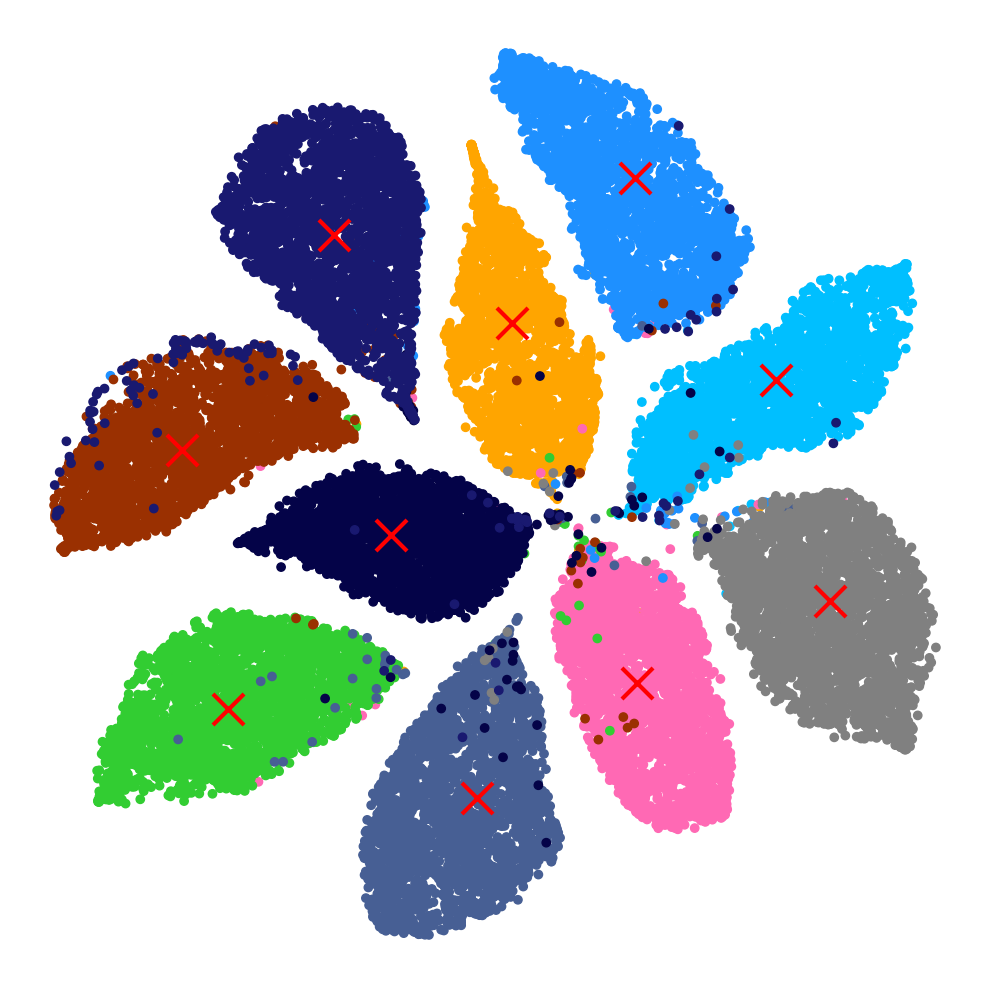

In [12]:
cluster_centers = autoencoder.get_cluster_centers().cpu().detach().numpy()
data, latent_data, labels = autoencoder.get_latent_data()
visualization.plot_tsne(latent_data, labels, clustering, cluster_centers, autoencoder.data_dir_path)